# 2. Log-likelihood landscapes for simple models  [MLE 1.3.6–1.4, 1.6.2]

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown, fixed

np.set_printoptions(precision=4, suppress=True)
import plotly.graph_objects as go
from scipy.stats import chi2, poisson, expon
from scipy.optimize import minimize

def check(label, ok):
    print(f"{'✓' if ok else '✗'}  {label}")

def hessian_fd(f, p, h=1e-4):
    # central finite-difference Hessian of a scalar function f at point p
    p = np.asarray(p, float); n = p.size; H = np.zeros((n, n)); E = np.eye(n) * h
    for i in range(n):
        for j in range(n):
            H[i, j] = (f(p + E[i] + E[j]) - f(p + E[i] - E[j]) - f(p - E[i] + E[j]) + f(p - E[i] - E[j])) / (4 * h * h)
    return H

def grad_fd(f, p, h=1e-6):
    p = np.asarray(p, float); E = np.eye(p.size) * h
    return np.array([(f(p + e) - f(p - e)) / (2 * h) for e in E])

---
## 2.1 Univariate Gaussian: a two-parameter landscape

**Task.** Sample $m = 20$ points from $\mathcal N(\mu = 1, \sigma^2 = 4)$. Plot the surface and contour lines of

$$\ell(\mu, \sigma^2) = -\frac m2\log(2\pi) - \frac m2\log\sigma^2 - \frac{\sum_i (y_i-\mu)^2}{2\sigma^2}$$

over a grid of $(\mu, \sigma^2)$. Mark the true parameters and $(\mu_{ML}, \sigma^2_{ML})$, and draw the gradient field $\nabla\ell$ as arrows.

### Prediction

- A single peak at $(\bar y, \frac1m\sum(y_i-\bar y)^2)$, close to but not exactly at $(1, 4)$.
- The contours are symmetric in $\mu$ (a parabola in $\mu$ for fixed $\sigma^2$) but skewed in $\sigma^2$: steep towards $\sigma^2 \to 0$, very flat towards large $\sigma^2$.
- As $m$ grows the peak sharpens (curvature $\propto m$) and moves towards the truth.

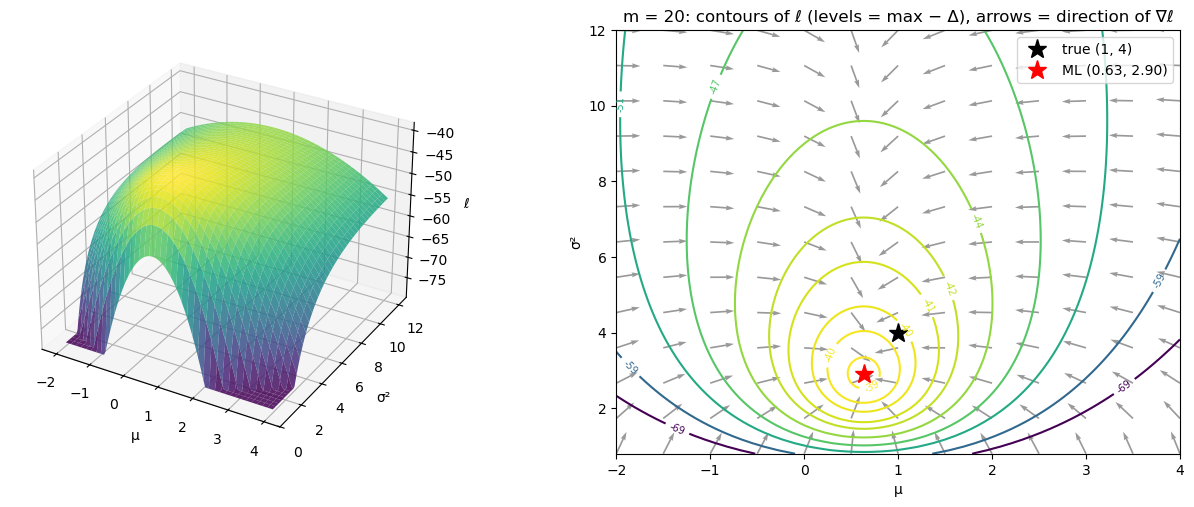

In [2]:
mu_true, s2_true = 1.0, 4.0

def gauss_loglik(mu, s2, y):
    m = y.size
    S = np.sum((y[:, None, None] - mu) ** 2, axis=0) if np.ndim(mu) else np.sum((y - mu) ** 2)
    return -m / 2 * np.log(2 * np.pi) - m / 2 * np.log(s2) - S / (2 * s2)

def gauss_grad(mu, s2, y):
    m = y.size
    S = np.sum((y[:, None, None] - mu) ** 2, axis=0)
    d_mu = (np.sum(y) - m * mu) / s2
    d_s2 = -m / (2 * s2) + S / (2 * s2**2)
    return d_mu, d_s2

def plot_landscape(m, seed=0, log_axis=False):
    y = np.random.default_rng(seed).normal(mu_true, np.sqrt(s2_true), m)
    mu_ml, s2_ml = y.mean(), np.mean((y - y.mean()) ** 2)
    mus = np.linspace(-2, 4, 121)
    s2s = np.exp(np.linspace(np.log(0.8), np.log(16), 121)) if log_axis else np.linspace(0.8, 12, 121)
    MU, S2 = np.meshgrid(mus, s2s)
    L = gauss_loglik(MU, S2, y)

    fig = plt.figure(figsize=(16, 5.5))
    ax3 = fig.add_subplot(1, 2, 1, projection="3d")
    ax3.plot_surface(MU, np.log(S2) if log_axis else S2, np.maximum(L, L.max() - 40), cmap="viridis", alpha=0.85, lw=0)
    ax3.set_xlabel("μ"); ax3.set_ylabel("log σ²" if log_axis else "σ²"); ax3.set_zlabel("ℓ")

    ax = fig.add_subplot(1, 2, 2)
    Yax = np.log(S2) if log_axis else S2
    cs = ax.contour(MU, Yax, L, levels=L.max() - np.array([30, 20, 12, 8, 5, 3, 2, 1, 0.5, 0.1])[::-1][::-1], cmap="viridis")
    ax.clabel(cs, fontsize=7, fmt="%.0f")
    Q = slice(None, None, 10)
    dmu, ds2 = gauss_grad(MU[Q, Q], S2[Q, Q], y)
    if log_axis:
        ds2 = ds2 * S2[Q, Q]                      # chain rule: dℓ/d(log σ²) = σ² dℓ/dσ²
    nrm = np.hypot(dmu, ds2) + 1e-12
    ax.quiver(MU[Q, Q], Yax[Q, Q], dmu / nrm, ds2 / nrm, color="gray", width=0.003, alpha=0.8)
    ax.plot(mu_true, np.log(s2_true) if log_axis else s2_true, "k*", ms=14, label="true (1, 4)")
    ax.plot(mu_ml, np.log(s2_ml) if log_axis else s2_ml, "r*", ms=14, label=f"ML ({mu_ml:.2f}, {s2_ml:.2f})")
    ax.set_xlabel("μ"); ax.set_ylabel("log σ²" if log_axis else "σ²"); ax.legend()
    ax.set_title(f"m = {m}: contours of ℓ (levels = max − Δ), arrows = direction of ∇ℓ")
    plt.show()
    return y, mu_ml, s2_ml

y, mu_ml, s2_ml = plot_landscape(20)

### Verify numerically: gradient zero and Hessian negative definite at the ML point

In [3]:
f = lambda p: gauss_loglik(p[0], p[1], y)
m = y.size
g_ml = grad_fd(f, [mu_ml, s2_ml])
H_ml = hessian_fd(f, [mu_ml, s2_ml])
H_formula = np.diag([-m / s2_ml, -m / (2 * s2_ml**2)])
print("∇ℓ at ML  =", g_ml)
print("Hessian   =\n", H_ml, "\nformula   =\n", H_formula)
check("∇ℓ(μ_ML, σ²_ML) = 0", np.allclose(g_ml, 0, atol=1e-5))
check("Hessian = diag(−m/σ², −m/(2σ⁴)) at the ML point", np.allclose(H_ml, H_formula, rtol=1e-3, atol=1e-4))
check("Hessian is negative definite (both eigenvalues < 0)", np.all(np.linalg.eigvalsh(H_ml) < 0))
check("μ_ML = mean(y), σ²_ML = mean((y − ȳ)²)", np.isclose(mu_ml, y.mean()) and np.isclose(s2_ml, y.var()))

∇ℓ at ML  = [0. 0.]
Hessian   =
 [[-6.9062  0.    ]
 [ 0.     -1.1924]] 
formula   =
 [[-6.9062  0.    ]
 [ 0.     -1.1924]]
✓  ∇ℓ(μ_ML, σ²_ML) = 0
✓  Hessian = diag(−m/σ², −m/(2σ⁴)) at the ML point
✓  Hessian is negative definite (both eigenvalues < 0)
✓  μ_ML = mean(y), σ²_ML = mean((y − ȳ)²)


### Explore: m = 200 and 2,000; slices; log σ² on the vertical axis

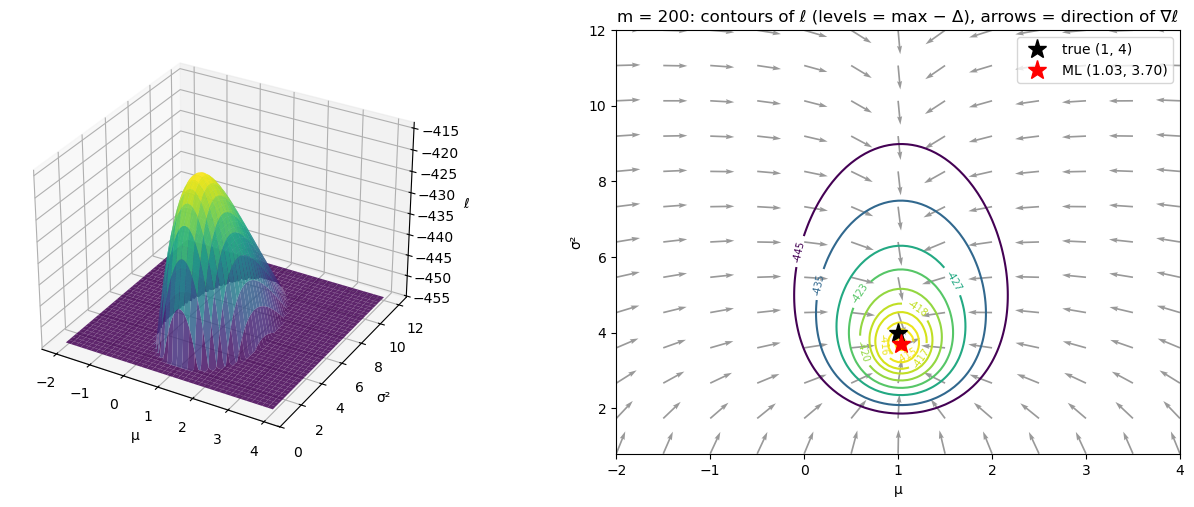

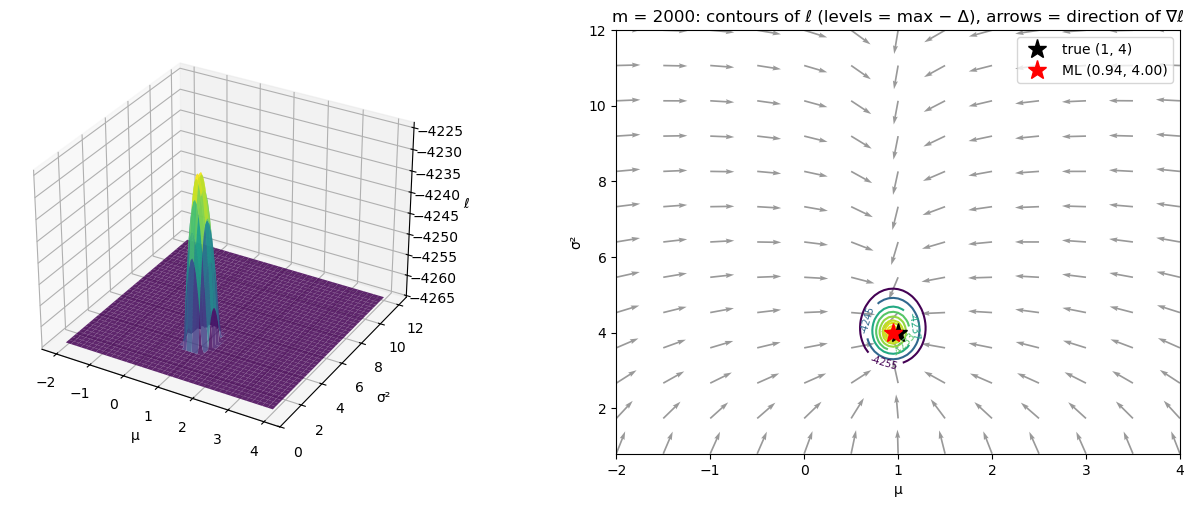

In [4]:
for m_ in [200, 2000]:
    plot_landscape(m_)

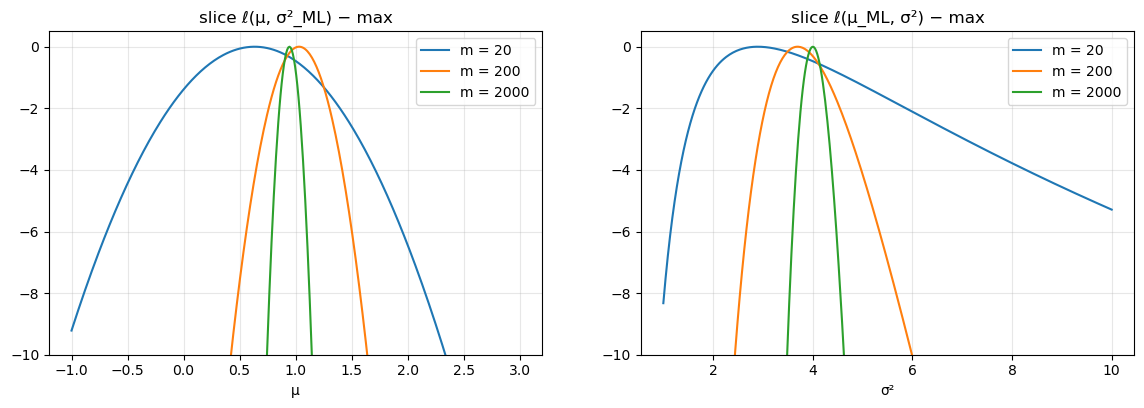

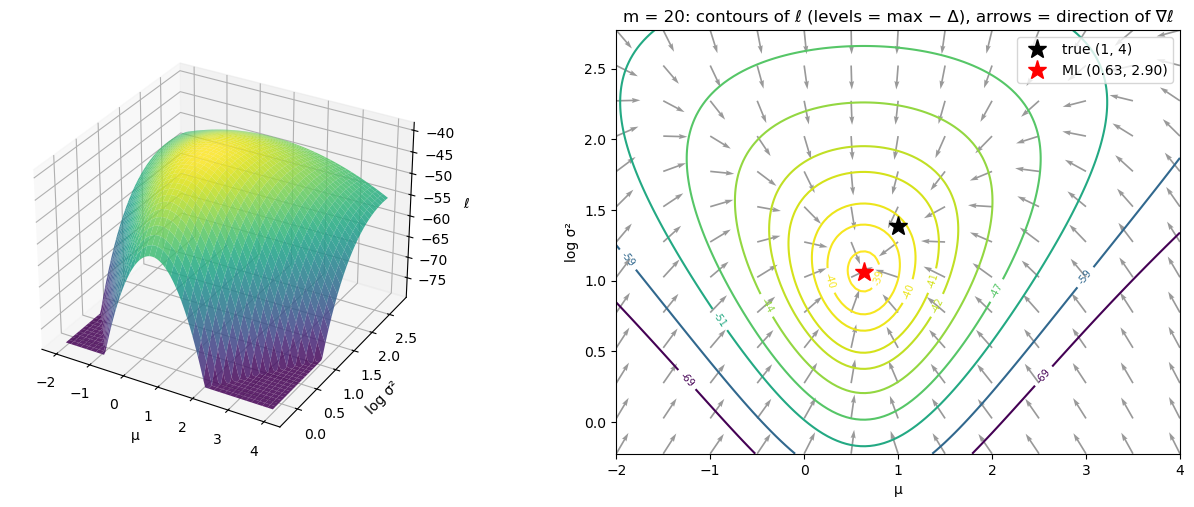

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
for m_ in [20, 200, 2000]:
    yy = np.random.default_rng(0).normal(mu_true, np.sqrt(s2_true), m_)
    mm, ss = yy.mean(), yy.var()
    mus, s2s = np.linspace(-1, 3, 400), np.linspace(1, 10, 400)
    l1 = np.array([gauss_loglik(u, ss, yy) for u in mus]); l2 = np.array([gauss_loglik(mm, s, yy) for s in s2s])
    ax1.plot(mus, l1 - l1.max(), label=f"m = {m_}"); ax2.plot(s2s, l2 - l2.max(), label=f"m = {m_}")
ax1.set_title("slice ℓ(μ, σ²_ML) − max"); ax1.set_xlabel("μ"); ax1.set_ylim(-10, 0.5)
ax2.set_title("slice ℓ(μ_ML, σ²) − max"); ax2.set_xlabel("σ²"); ax2.set_ylim(-10, 0.5)
for ax in (ax1, ax2):
    ax.legend(); ax.grid(alpha=0.3)
plt.show()
_ = plot_landscape(20, log_axis=True)

### Is ℓ jointly concave? Three parametrisations

We compute the Hessian by finite differences on a grid and colour the points where it is **not** negative semidefinite.
- $(\mu, \sigma^2)$ — the parametrisation above
- $(\mu, \tau)$ with the precision $\tau = 1/\sigma^2$: $\ell = -\frac m2\log 2\pi + \frac m2\log\tau - \frac\tau2\sum_i(y_i-\mu)^2$
- natural parameters $(\eta_1, \eta_2) = (\tau\mu, \tau)$: $\ell = -\frac m2\log2\pi + \frac m2\log\eta_2 - \frac{\eta_2}{2}\sum y_i^2 + \eta_1\sum y_i - \frac{m\eta_1^2}{2\eta_2}$

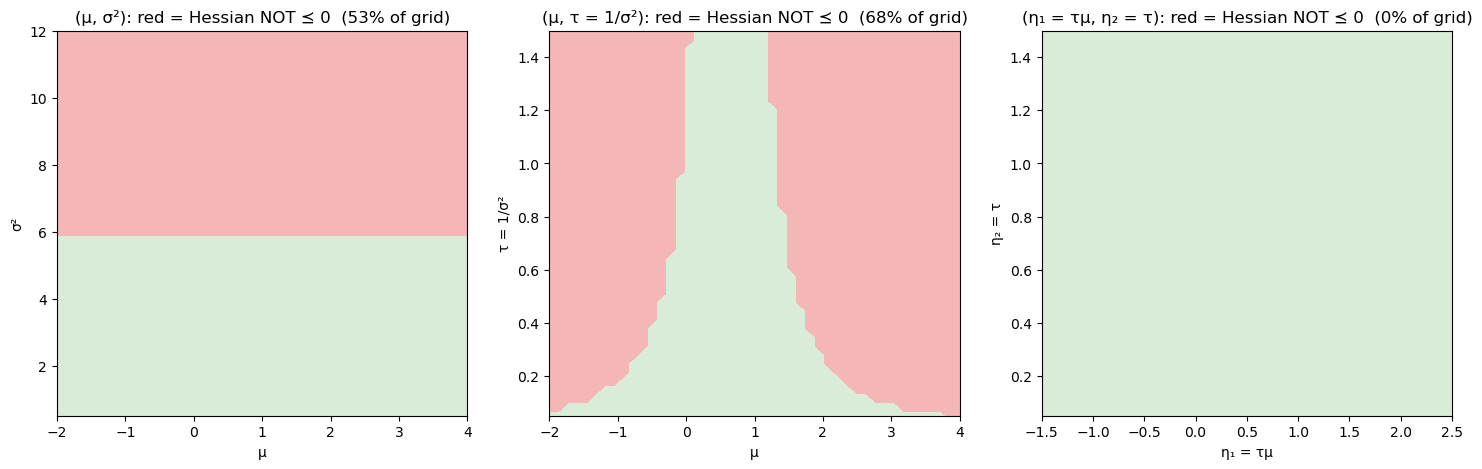

In [6]:
Sy, Syy, m = y.sum(), np.sum(y**2), y.size
param = {
    "(μ, σ²)": (lambda p: gauss_loglik(p[0], p[1], y), (-2, 4), (0.5, 12)),
    "(μ, τ = 1/σ²)": (lambda p: -m/2*np.log(2*np.pi) + m/2*np.log(p[1]) - p[1]/2*np.sum((y - p[0])**2), (-2, 4), (0.05, 1.5)),
    "(η₁ = τμ, η₂ = τ)": (lambda p: -m/2*np.log(2*np.pi) + m/2*np.log(p[1]) - p[1]/2*Syy + p[0]*Sy - m*p[0]**2/(2*p[1]), (-1.5, 2.5), (0.05, 1.5)),
}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (fun, xr, yr)) in zip(axes, param.items()):
    A, B = np.meshgrid(np.linspace(*xr, 45), np.linspace(*yr, 45))
    lam_max = np.array([[np.linalg.eigvalsh(hessian_fd(fun, [a, b], h=1e-3)).max() for a, b in zip(ra, rb)]
                        for ra, rb in zip(A, B)])
    bad = lam_max > 1e-6
    ax.contourf(A, B, bad, levels=[-0.5, 0.5, 1.5], colors=["#d8ecd8", "#f4b6b6"])
    ax.set_title(f"{name}: red = Hessian NOT ⪯ 0  ({bad.mean():.0%} of grid)")
    ax.set_xlabel(name.split(",")[0].strip("( ")); ax.set_ylabel(name.split(",")[1].strip(") "))
plt.show()

---
### Explain

**1. Check that the gradient vanishes at $(\mu_{ML}, \sigma^2_{ML})$ and that the Hessian there is negative definite.**

Done above: the finite-difference gradient is $\approx 0$ and the Hessian equals $\mathrm{diag}(-m/\sigma^2_{ML},\ -m/(2\sigma^4_{ML}))$, both eigenvalues negative. The mixed term $\partial^2\ell/\partial\mu\,\partial\sigma^2 = -\sum_i(y_i-\mu)/\sigma^4$ vanishes at $\mu = \bar y$, so at the maximum the two parameters decouple locally.

**2. Why does $\mu_{ML}$ not depend on $\sigma^2$, while $\sigma^2_{ML}$ depends on $\mu_{ML}$?**

$\partial\ell/\partial\mu = \sum_i(y_i-\mu)/\sigma^2 = 0$: the factor $1/\sigma^2$ is a positive constant that multiplies the whole equation, so the root $\mu = \bar y$ is the same for every $\sigma^2$ (geometrically, every horizontal slice of the landscape peaks at the same $\mu$). The other equation, $\partial\ell/\partial\sigma^2 = -\frac{m}{2\sigma^2} + \frac{\sum(y_i-\mu)^2}{2\sigma^4} = 0$, gives $\sigma^2 = \frac1m\sum(y_i-\mu)^2$, which contains $\mu$; the joint maximum plugs in $\mu = \mu_{ML}$. That is also why $\sigma^2_{ML}$ is biased (Exercise 2.2): it measures spread around the *estimated* mean.

**3. Is $\ell$ jointly concave in $(\mu, \sigma^2)$? Try parametrising with the precision $\tau = 1/\sigma^2$ instead.**

**Not in $(\mu, \sigma^2)$.** For fixed $\mu$, $\partial^2\ell/\partial(\sigma^2)^2 = \frac{m}{2\sigma^4} - \frac{S}{\sigma^6}$ (with $S = \sum(y_i-\mu)^2$) becomes **positive** once $\sigma^2 > 2S/m$: the landscape curls upwards for large variances (the red region in the left panel). The slices also show it: the $\sigma^2$ slice is asymmetric with a flattening right tail.

**In $(\mu, \tau)$ it is concave in each variable separately** ($\partial^2_\tau\ell = -m/(2\tau^2) < 0$ and $\partial^2_\mu\ell = -m\tau < 0$), but **still not jointly**: $\det H = \frac{m^2}{2\tau} - m^2(\bar y - \mu)^2$ is negative when $\tau(\bar y-\mu)^2 > 1/2$, i.e. far from $\bar y$ in $\mu$ (red region in the middle panel). Near the maximum it is fine.

**In the natural parameters $(\eta_1, \eta_2) = (\tau\mu, \tau)$ it is jointly concave** (right panel: no red at all): $\frac m2\log\eta_2$ is concave, $\eta_1\sum y_i - \frac{\eta_2}{2}\sum y_i^2$ is linear, and $-\frac{m\eta_1^2}{2\eta_2}$ is minus a quadratic-over-linear function, which is convex. This is the general fact that exponential-family log-likelihoods are concave in their natural parameters, and the reason Exercise 4.5 finds a convex problem for the precision matrix. The maximiser is the same point in every parametrisation; only the *shape* of the landscape, and therefore the behaviour of optimisation algorithms, changes.

---
## 2.2 The bias of $\sigma^2_{ML}$

**Task.** Simulate 50,000 data sets of size $m$ from $\mathcal N(0, 1)$ and plot the histograms of $\sigma^2_{ML} = \frac1m\sum_i(y_i-\mu_{ML})^2$ and of the unbiased version $\frac{1}{m-1}\sum_i(y_i-\mu_{ML})^2$. Plot $E(\sigma^2_{ML})$, the variance and the MSE of both estimators against $m$.

$$E(\sigma^2_{ML}) = \frac{m-1}{m}\sigma^2, \qquad \mathrm{MSE} = b^2 + \mathrm{Var}.$$

Theory for Gaussian data ($m\sigma^2_{ML}/\sigma^2 \sim \chi^2_{m-1}$): $\mathrm{Var}(\sigma^2_{ML}) = \frac{2(m-1)}{m^2}\sigma^4$, $\mathrm{Var}(s^2_{unb}) = \frac{2}{m-1}\sigma^4$.

### Prediction

- $\sigma^2_{ML}$ sits slightly to the left of 1 (mean $(m-1)/m$); the unbiased one is centred at 1 but wider.
- The ML version has the **smaller** MSE: its small bias is more than paid back by its smaller variance.

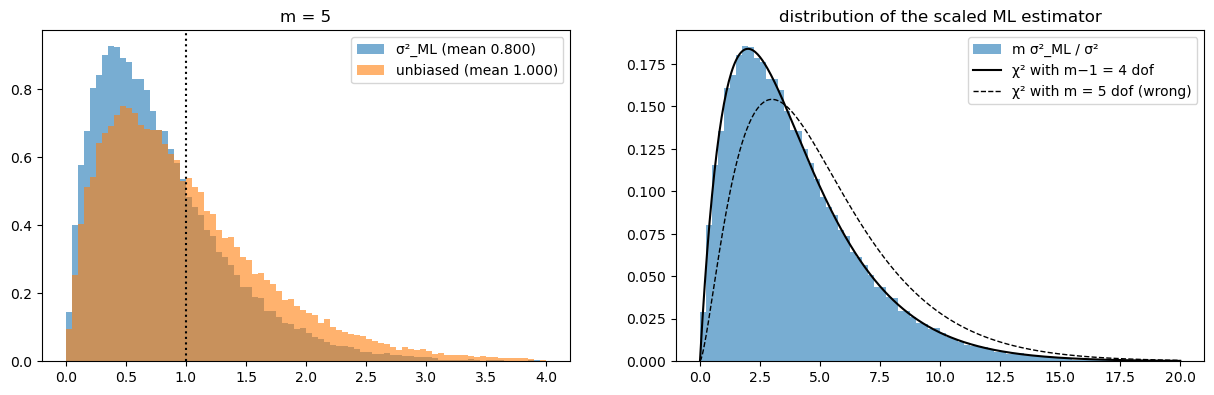

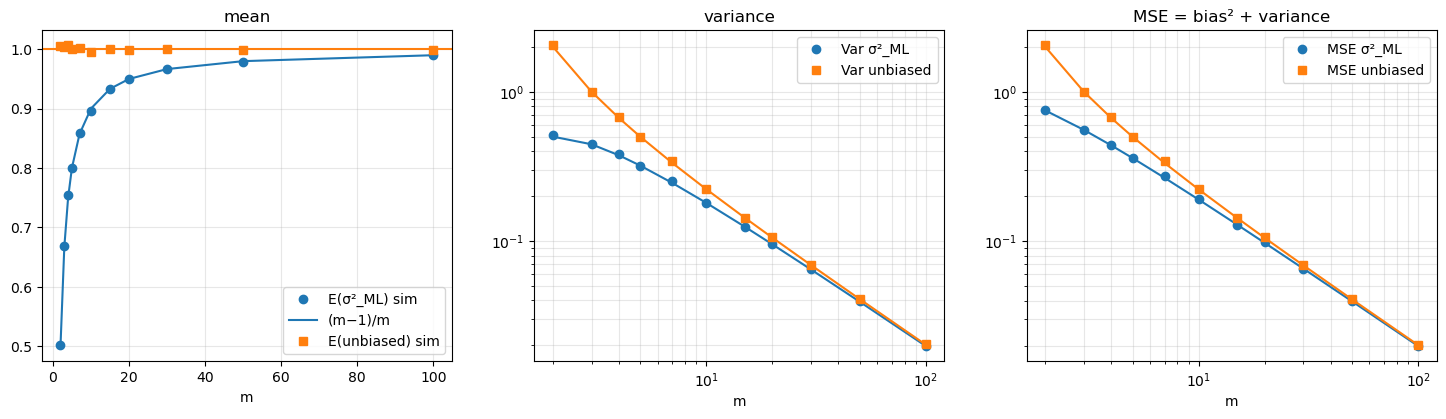

In [7]:
n_sets = 50_000
rng = np.random.default_rng(0)
ms = np.array([2, 3, 4, 5, 7, 10, 15, 20, 30, 50, 100])
stats = []
for m in ms:
    Y = rng.standard_normal((n_sets, m))
    ss = np.sum((Y - Y.mean(axis=1, keepdims=True)) ** 2, axis=1)
    s2_ml, s2_unb = ss / m, ss / (m - 1)
    stats.append([s2_ml.mean(), s2_unb.mean(), s2_ml.var(), s2_unb.var(), np.mean((s2_ml - 1)**2), np.mean((s2_unb - 1)**2)])
    if m == 5:
        hist_ml, hist_unb = s2_ml, s2_unb
stats = np.array(stats)

m = 5
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
bins = np.linspace(0, 4, 81)
axes[0].hist(hist_ml, bins, density=True, alpha=0.6, label=f"σ²_ML (mean {hist_ml.mean():.3f})")
axes[0].hist(hist_unb, bins, density=True, alpha=0.6, label=f"unbiased (mean {hist_unb.mean():.3f})")
axes[0].axvline(1, color="k", ls=":"); axes[0].legend(); axes[0].set_title(f"m = {m}")
u = np.linspace(0, 20, 400)
axes[1].hist(m * hist_ml, bins=np.linspace(0, 20, 81), density=True, alpha=0.6, label="m σ²_ML / σ²")
axes[1].plot(u, chi2.pdf(u, m - 1), "k", label=f"χ² with m−1 = {m-1} dof")
axes[1].plot(u, chi2.pdf(u, m), "k--", lw=1, label=f"χ² with m = {m} dof (wrong)")
axes[1].legend(); axes[1].set_title("distribution of the scaled ML estimator")
plt.show()

theory = {"E_ml": (ms - 1) / ms, "V_ml": 2 * (ms - 1) / ms**2, "V_unb": 2 / (ms - 1),
          "MSE_ml": (2 * ms - 1) / ms**2, "MSE_unb": 2 / (ms - 1)}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
axes[0].plot(ms, stats[:, 0], "o", label="E(σ²_ML) sim"); axes[0].plot(ms, theory["E_ml"], "C0-", label="(m−1)/m")
axes[0].plot(ms, stats[:, 1], "s", label="E(unbiased) sim"); axes[0].axhline(1, color="C1")
axes[1].loglog(ms, stats[:, 2], "o", label="Var σ²_ML"); axes[1].loglog(ms, theory["V_ml"], "C0-")
axes[1].loglog(ms, stats[:, 3], "s", label="Var unbiased"); axes[1].loglog(ms, theory["V_unb"], "C1-")
axes[2].loglog(ms, stats[:, 4], "o", label="MSE σ²_ML"); axes[2].loglog(ms, theory["MSE_ml"], "C0-")
axes[2].loglog(ms, stats[:, 5], "s", label="MSE unbiased"); axes[2].loglog(ms, theory["MSE_unb"], "C1-")
for ax, t in zip(axes, ["mean", "variance", "MSE = bias² + variance"]):
    ax.set_xlabel("m"); ax.set_title(t); ax.legend(); ax.grid(alpha=0.3, which="both")
plt.show()

### Verify numerically

In [8]:
check("E(σ²_ML) = (m−1)/m σ²", np.allclose(stats[:, 0], theory["E_ml"], atol=0.01))
check("E(unbiased) = σ²", np.allclose(stats[:, 1], 1, atol=0.015))
check("Var(σ²_ML) and Var(unbiased) match theory (within 5%)",
      np.allclose(stats[:, 2], theory["V_ml"], rtol=0.05) and np.allclose(stats[:, 3], theory["V_unb"], rtol=0.05))
check("MSE = bias² + Var for the ML estimator", np.allclose(stats[:, 4], (stats[:, 0] - 1)**2 + stats[:, 2], rtol=1e-6))
check("MSE(σ²_ML) < MSE(unbiased) for every m", np.all(stats[:, 4] < stats[:, 5]))

✓  E(σ²_ML) = (m−1)/m σ²
✓  E(unbiased) = σ²
✓  Var(σ²_ML) and Var(unbiased) match theory (within 5%)
✓  MSE = bias² + Var for the ML estimator
✓  MSE(σ²_ML) < MSE(unbiased) for every m


---
### Explain

**1. Which estimator has the smaller MSE for small $m$? Relate your answer to the bias–variance trade-off [MLE 1.5].**

The **ML (biased) estimator** — in fact for every $m \ge 2$, and the gap is largest for small $m$ (at $m = 2$: MSE 0.75 vs 2.0). In formulas, $\mathrm{MSE}_{ML} = \frac{1}{m^2}\sigma^4 + \frac{2(m-1)}{m^2}\sigma^4 = \frac{2m-1}{m^2}\sigma^4$ while $\mathrm{MSE}_{unb} = \frac{2}{m-1}\sigma^4$, and $\frac{2m-1}{m^2} < \frac{2}{m-1}$ always. Dividing by $m$ instead of $m-1$ shrinks the estimate towards 0: this introduces a bias $-\sigma^2/m$ (contributing only $\sigma^4/m^2$) but reduces the variance by the factor $\big(\frac{m-1}{m}\big)^2$, which saves more. This is exactly the trade-off of [MLE 1.5]: *unbiased* is not the same as *best*; a little bias can buy a larger reduction in variance. (Dividing by $m+1$ would minimise the MSE among estimators of the form $c\sum(y_i-\bar y)^2$.) For large $m$ all versions coincide.

**2. Compare the histogram of $m\,\sigma^2_{ML}/\sigma^2$ with a $\chi^2_{m-1}$ density.**

They match (right panel above), while a $\chi^2_m$ density is visibly shifted to the right. $m\sigma^2_{ML}/\sigma^2 = \sum_i (y_i - \bar y)^2/\sigma^2$ is a sum of $m$ squared standardised deviations, but they are not independent: they satisfy one linear constraint $\sum_i(y_i - \bar y) = 0$. Geometrically, $y - \bar y\mathbf 1$ is the projection of the Gaussian vector onto the $(m-1)$-dimensional subspace orthogonal to $\mathbf 1$, so its squared norm is $\chi^2$ with $m-1$ degrees of freedom. Its mean $m-1$ gives the bias $E(\sigma^2_{ML}) = \frac{m-1}{m}\sigma^2$ directly.

---
## 2.3 Other one-parameter models

**Task.** Derive $\hat\theta_{ML}$ by hand and plot the normalised log-likelihood $\frac1m\log p(y\mid\theta)$ for: (a) Poisson, $p(y\mid\lambda) = e^{-\lambda}\lambda^y/y!$; (b) exponential, $f(y\mid\lambda) = \lambda e^{-\lambda y}$; (c) uniform on $[0,\theta]$; (d) Gaussian with known $\sigma^2$ and unknown $\mu$. Use the same simulated $m$ for all four and put them in a $2\times2$ panel.

**Derivations** (with $\bar y = \frac1m\sum y_i$):

| model | $\frac1m\log p(y\mid\theta)$ | $\hat\theta_{ML}$ | Fisher info per sample $I(\theta)$ |
|---|---|---|---|
| (a) Poisson | $-\lambda + \bar y\log\lambda - \frac1m\sum\log y_i!$ | $\bar y$ | $1/\lambda$ |
| (b) exponential | $\log\lambda - \lambda\bar y$ | $1/\bar y$ | $1/\lambda^2$ |
| (c) uniform | $-\log\theta$ if $\theta \ge \max_i y_i$, else $-\infty$ | $\max_i y_i$ | not defined (support depends on $\theta$) |
| (d) Gaussian, known $\sigma^2$ | $-\frac12\log 2\pi\sigma^2 - \frac{1}{2m\sigma^2}\sum(y_i-\mu)^2$ | $\bar y$ | $1/\sigma^2$ |

Quadratic approximation [MLE 1.3.9], normalised: $\frac1m\ell(\theta) \approx \frac1m\ell(\hat\theta) - \frac12 I(\hat\theta)(\theta-\hat\theta)^2$.

### Prediction

- (a), (b), (d) have smooth concave curves with a peak where the derivative is zero; for (d) the quadratic approximation is exact.
- (c) is a ramp that jumps from $-\infty$ to its maximum at $\max y_i$ and then decreases: the maximum is at a corner, not at a zero derivative.

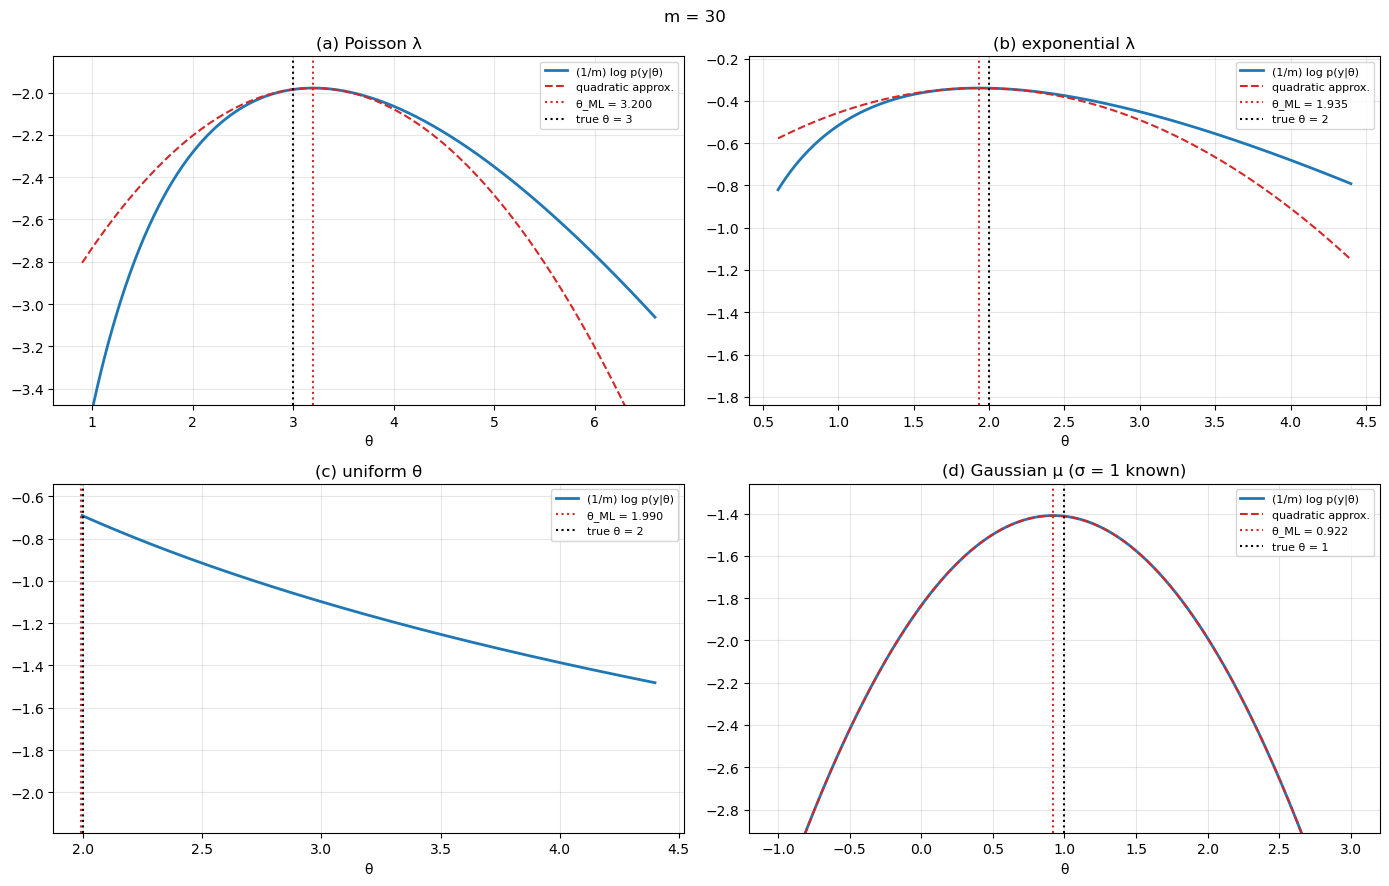

In [9]:
from scipy.special import gammaln

models = {
    "(a) Poisson λ": dict(true=3.0, sample=lambda r, m, t: r.poisson(t, m),
                          ll=lambda th, y: -th + y.mean() * np.log(th) - gammaln(y + 1).mean(),
                          ml=lambda y: y.mean(), I=lambda th: 1 / th),
    "(b) exponential λ": dict(true=2.0, sample=lambda r, m, t: r.exponential(1 / t, m),
                              ll=lambda th, y: np.log(th) - th * y.mean(),
                              ml=lambda y: 1 / y.mean(), I=lambda th: 1 / th**2),
    "(c) uniform θ": dict(true=2.0, sample=lambda r, m, t: r.uniform(0, t, m),
                          ll=lambda th, y: np.where(th >= y.max(), -np.log(th), -np.inf),
                          ml=lambda y: y.max(), I=None),
    "(d) Gaussian μ (σ = 1 known)": dict(true=1.0, sample=lambda r, m, t: r.normal(t, 1.0, m),
                          ll=lambda th, y: -0.5 * np.log(2 * np.pi) - np.mean((y[:, None] - th) ** 2, axis=0) / 2,
                          ml=lambda y: y.mean(), I=lambda th: 1.0),
}

def plot_models(m=30, scale=1.0, seed=0):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for ax, (name, M) in zip(axes.ravel(), models.items()):
        t = M["true"] * scale
        y = M["sample"](rng, m, t)
        th_hat = M["ml"](y)
        grid = np.linspace(0.3 * t, 2.2 * t, 600) if "Gaussian" not in name else np.linspace(t - 2, t + 2, 600)
        ll = M["ll"](grid, y)
        ax.plot(grid, ll, lw=2, label="(1/m) log p(y|θ)")
        ll_hat = M["ll"](np.array([th_hat]), y)[0]
        if M["I"] is not None:
            ax.plot(grid, ll_hat - 0.5 * M["I"](th_hat) * (grid - th_hat) ** 2, "C3--", label="quadratic approx.")
        ax.axvline(th_hat, color="C3", ls=":", label=f"θ_ML = {th_hat:.3f}")
        ax.axvline(t, color="k", ls=":", label=f"true θ = {t:.3g}")
        finite = ll[np.isfinite(ll)]
        ax.set_ylim(finite.max() - 1.5, finite.max() + 0.15)
        ax.set_title(name); ax.legend(fontsize=8); ax.grid(alpha=0.3); ax.set_xlabel("θ")
    fig.suptitle(f"m = {m}")
    plt.tight_layout(); plt.show()

plot_models()

### Verify numerically

In [10]:
rng = np.random.default_rng(1)
m = 30
for name, M in models.items():
    y = M["sample"](rng, m, M["true"])
    grid = np.linspace(0.2 * M["true"], 3 * M["true"], 200_001) if "Gaussian" not in name else np.linspace(-3, 5, 200_001)
    th_grid = grid[np.argmax(M["ll"](grid, y))]
    check(f"{name}: hand-derived θ_ML = {M['ml'](y):.4f} matches the grid argmax {th_grid:.4f}",
          np.isclose(M["ml"](y), th_grid, atol=2e-4 * max(1, M["true"])))

# Rao–Cramér: Var(θ̂) ≥ 1/(m I(θ)) for unbiased estimators (simulation with 20,000 data sets of size m = 30)
print()
n_sets = 20_000
for name, M in models.items():
    est = np.array([M["ml"](M["sample"](rng, m, M["true"])) for _ in range(n_sets)])
    bound = 1 / (m * M["I"](M["true"])) if M["I"] else np.nan
    print(f"{name:<30} mean θ̂ = {est.mean():.4f} (true {M['true']})   Var θ̂ = {est.var():.5f}   1/(m I) = {bound:.5f}")

✓  (a) Poisson λ: hand-derived θ_ML = 3.2667 matches the grid argmax 3.2667
✓  (b) exponential λ: hand-derived θ_ML = 1.6729 matches the grid argmax 1.6729
✓  (c) uniform θ: hand-derived θ_ML = 1.9981 matches the grid argmax 1.9981
✓  (d) Gaussian μ (σ = 1 known): hand-derived θ_ML = 0.8904 matches the grid argmax 0.8904

(a) Poisson λ                  mean θ̂ = 2.9977 (true 3.0)   Var θ̂ = 0.10144   1/(m I) = 0.10000
(b) exponential λ              mean θ̂ = 2.0664 (true 2.0)   Var θ̂ = 0.15414   1/(m I) = 0.13333
(c) uniform θ                  mean θ̂ = 1.9355 (true 2.0)   Var θ̂ = 0.00383   1/(m I) = nan
(d) Gaussian μ (σ = 1 known)   mean θ̂ = 1.0012 (true 1.0)   Var θ̂ = 0.03348   1/(m I) = 0.03333


### Explore: vary m and the true parameter (scale)

In [11]:
@interact(m=IntSlider(min=5, max=500, step=5, value=30), scale=FloatSlider(min=0.5, max=3, step=0.25, value=1.0),
          seed=IntSlider(min=0, max=20, value=0))
def explore_models(m, scale, seed):
    plot_models(m, scale, seed)

interactive(children=(IntSlider(value=30, description='m', max=500, min=5, step=5), FloatSlider(value=1.0, des…

---
### Explain

**1. In which model is the log-likelihood *not* differentiable at its maximum, so that setting the derivative to zero fails?**

**(c) the uniform on $[0,\theta]$.** The likelihood is $\theta^{-m}$ if $\theta \ge \max_i y_i$ and 0 otherwise (one observation outside $[0,\theta]$ is impossible). It is strictly *decreasing* wherever it is positive, so its derivative is never zero; the maximum is at the left edge of the allowed region, $\hat\theta = \max_i y_i$, where the function jumps from $-\infty$ (log scale) to its largest value. The "regularity conditions" behind Fisher information and the quadratic approximation fail because the support of the distribution depends on $\theta$. Consequences: $\hat\theta$ is biased ($E = \frac{m}{m+1}\theta$, always below the truth) and its variance shrinks like $1/m^2$ rather than $1/m$ (see the simulation table: it is far smaller than any $1/(mI)$-type bound would suggest).

**2. Where is the quadratic approximation good and where bad?**

It is a second-order Taylor expansion around $\hat\theta$, so it is good **near the maximum** and degrades away from it. For (d) it is **exact**, because the Gaussian log-likelihood in $\mu$ is itself a quadratic. For (a) and (b) it is good within roughly one standard error of $\hat\theta$ and bad in the tails, especially on the side towards $\theta \to 0$, where the true log-likelihood falls to $-\infty$ ($\log\lambda$ terms) while the parabola stays finite; the curves are skewed and the parabola is symmetric. Increasing $m$ (slider) makes the relevant region around $\hat\theta$ shrink like $1/\sqrt m$, so on that scale the approximation keeps improving: this is why ML estimators become Gaussian for large $m$. For (c) there is no quadratic approximation at all.

**3. Relate the curvature at the maximum to the Fisher information and to the Rao–Cramér bound [MLE 1.3.8].**

The curvature of the normalised log-likelihood at $\hat\theta$ is $-\frac1m\frac{d^2\ell}{d\theta^2} \approx I(\hat\theta)$ (for (a) it is exactly $\bar y/\hat\lambda^2 = 1/\hat\lambda$, for (b) $1/\hat\lambda^2$, for (d) $1/\sigma^2$). A sharply curved peak means the data discriminate strongly between nearby $\theta$ values, i.e. a lot of information. The Rao–Cramér bound says any unbiased estimator has $\mathrm{Var}(\hat\theta) \ge \frac{1}{m\,I(\theta)}$ (the notes write $1/I(\theta)$ with $I$ defined per sample; the factor $m$ is needed for consistency with their definition). In the simulation, (a) Poisson and (d) Gaussian reach the bound exactly ($\bar y$ is efficient); (b) is slightly above it and also slightly biased ($E(1/\bar y) = \frac{m}{m-1}\lambda$); both effects vanish as $m$ grows. So: curvature $\approx m I$ ⇒ asymptotic variance $\approx 1/(mI)$ = inverse curvature.

---
## 2.4 Multivariate Gaussian

**Task.** Sample $m$ points from a 2-D Gaussian (reuse the $\Sigma = Q\Lambda Q^\top$ construction from the Linear Algebra portfolio). Compute $\mu_{ML}$ and $\Sigma_{ML}$ and check them against `np.mean` and `np.cov(..., bias=True)`. Plot the log-likelihood as a function of $\mu$ (with $\Sigma = \Sigma_{ML}$ fixed) as a contour map.

$$\ell(\mu, \Sigma) = -\frac{mn}{2}\log(2\pi) - \frac m2\log|\Sigma| - \frac12\sum_i (y_i-\mu)^\top\Sigma^{-1}(y_i-\mu).$$

### Prediction

- $\ell(\mu)$ is a concave quadratic in $\mu$ with maximum at $\bar y$; its contours are ellipses with the same orientation as the data cloud, but $\sqrt m$ times smaller.

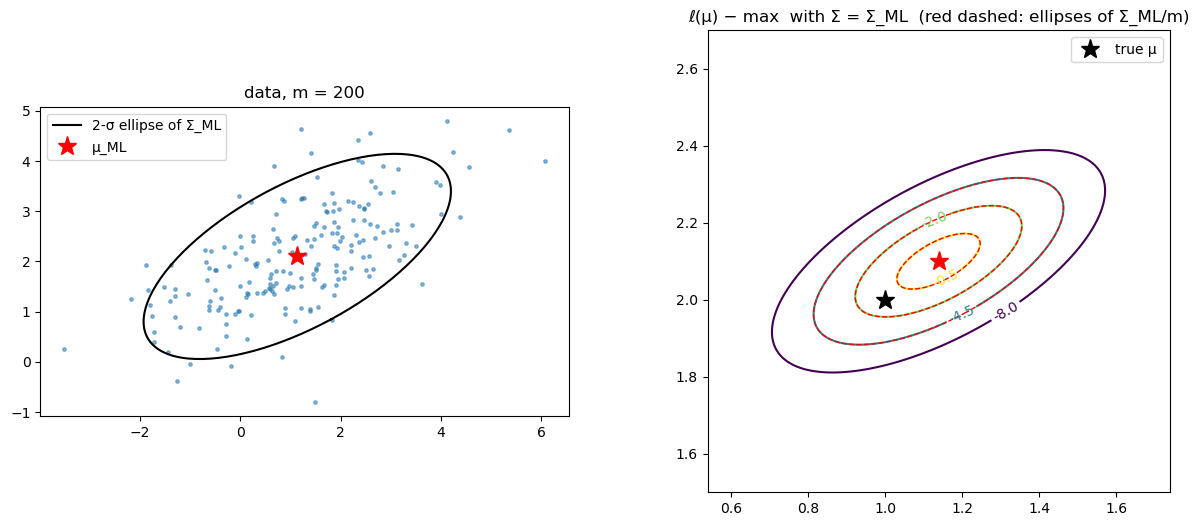

In [12]:
def rot(deg):
    t = np.deg2rad(deg); return np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])

Q = rot(30)
Sigma_true = Q @ np.diag([3.0, 0.5]) @ Q.T
mu_true2 = np.array([1.0, 2.0])
m, n = 200, 2
Y = np.random.default_rng(0).multivariate_normal(mu_true2, Sigma_true, m)

mu_ml = Y.mean(axis=0)
D = Y - mu_ml
Sigma_ml = D.T @ D / m
S_inv = np.linalg.inv(Sigma_ml)

def loglik_mvn(mu, Sigma, Y):
    m, n = Y.shape
    D = Y - mu
    return (-m * n / 2 * np.log(2 * np.pi) - m / 2 * np.log(np.linalg.det(Sigma))
            - 0.5 * np.einsum("ij,jk,ik->", D, np.linalg.inv(Sigma), D))

g1 = np.linspace(mu_ml[0] - 0.6, mu_ml[0] + 0.6, 121); g2 = np.linspace(mu_ml[1] - 0.6, mu_ml[1] + 0.6, 121)
M1, M2 = np.meshgrid(g1, g2)
L = np.array([[loglik_mvn(np.array([a, b]), Sigma_ml, Y) for a, b in zip(r1, r2)] for r1, r2 in zip(M1, M2)])

def ellipse(c, S, r, k=200):
    lam, V = np.linalg.eigh(S); ph = np.linspace(0, 2 * np.pi, k)
    return c[:, None] + V @ (r * np.sqrt(lam)[:, None] * np.vstack([np.cos(ph), np.sin(ph)]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
ax1.scatter(*Y.T, s=6, alpha=0.5); ax1.plot(*ellipse(mu_ml, Sigma_ml, 2), "k", label="2-σ ellipse of Σ_ML")
ax1.plot(*mu_ml, "r*", ms=14, label="μ_ML"); ax1.set_aspect("equal"); ax1.legend(); ax1.set_title(f"data, m = {m}")
cs = ax2.contour(M1, M2, L - L.max(), levels=-np.array([8, 4.5, 2, 0.5])[::1][::-1][::-1], cmap="viridis")
ax2.clabel(cs, fmt="%.1f")
for c in [1, 2, 3]:
    ax2.plot(*ellipse(mu_ml, Sigma_ml / m, c), "r--", lw=1)
ax2.plot(*mu_ml, "r*", ms=14); ax2.plot(*mu_true2, "k*", ms=14, label="true μ")
ax2.set_aspect("equal"); ax2.legend()
ax2.set_title("ℓ(μ) − max  with Σ = Σ_ML  (red dashed: ellipses of Σ_ML/m)")
plt.show()

### Verify numerically

In [13]:
check("μ_ML = np.mean", np.allclose(mu_ml, np.mean(Y, axis=0)))
check("Σ_ML = np.cov(..., bias=True)", np.allclose(Sigma_ml, np.cov(Y.T, bias=True)))
# ℓ(μ) = ℓ(μ_ML) − m/2 (μ − μ_ML)ᵀ Σ⁻¹ (μ − μ_ML): exactly quadratic, contours = ellipses of Σ/m
mu_test = mu_ml + np.array([0.2, -0.1])
check("ℓ(μ) = ℓ(μ_ML) − (m/2)(μ−μ_ML)ᵀΣ⁻¹(μ−μ_ML)", np.isclose(
      loglik_mvn(mu_test, Sigma_ml, Y), loglik_mvn(mu_ml, Sigma_ml, Y) - m / 2 * (mu_test - mu_ml) @ S_inv @ (mu_test - mu_ml)))

# matrix-derivative identities of [MLE 1.3.7], by finite differences on each entry of Σ
rng = np.random.default_rng(3)
B = rng.standard_normal((2, 2)); Sig = B @ B.T + np.eye(2); A = rng.standard_normal((2, 2)); A = A @ A.T
def d_entry(fun, X, h=1e-6):
    G = np.zeros_like(X)
    for i in range(2):
        for j in range(2):
            E = np.zeros_like(X); E[i, j] = h
            G[i, j] = (fun(X + E) - fun(X - E)) / (2 * h)
    return G
Si = np.linalg.inv(Sig)
check("∂ log|Σ| / ∂Σ = Σ⁻ᵀ = Σ⁻¹", np.allclose(d_entry(lambda X: np.log(np.linalg.det(X)), Sig), Si.T, atol=1e-6))
check("∂ tr(Σ⁻¹A) / ∂Σ = −Σ⁻¹AΣ⁻¹  (note the minus sign)", np.allclose(d_entry(lambda X: np.trace(np.linalg.inv(X) @ A), Sig), -Si @ A @ Si, atol=1e-6))
check("xᵀΣ⁻¹x = tr(Σ⁻¹ x xᵀ)", np.isclose(D[0] @ S_inv @ D[0], np.trace(S_inv @ np.outer(D[0], D[0]))))
G = d_entry(lambda X: loglik_mvn(mu_ml, X, Y), Sigma_ml, h=1e-6)
check("∂ℓ/∂Σ = −(m/2)Σ⁻¹ + ½Σ⁻¹(Σ_i d_i d_iᵀ)Σ⁻¹ = 0 at Σ_ML", np.allclose(G, 0, atol=1e-3))

# precision-matrix form
Lam = np.linalg.inv(Sigma_ml); S = Sigma_ml
ell_prec = -m * n / 2 * np.log(2 * np.pi) + m / 2 * np.log(np.linalg.det(Lam)) - m / 2 * np.trace(Lam @ S)
check("ℓ = −mn/2 log 2π + (m/2) log det Λ − (m/2) tr(ΛS)", np.isclose(ell_prec, loglik_mvn(mu_ml, Sigma_ml, Y)))

✓  μ_ML = np.mean
✓  Σ_ML = np.cov(..., bias=True)
✓  ℓ(μ) = ℓ(μ_ML) − (m/2)(μ−μ_ML)ᵀΣ⁻¹(μ−μ_ML)
✓  ∂ log|Σ| / ∂Σ = Σ⁻ᵀ = Σ⁻¹
✓  ∂ tr(Σ⁻¹A) / ∂Σ = −Σ⁻¹AΣ⁻¹  (note the minus sign)
✓  xᵀΣ⁻¹x = tr(Σ⁻¹ x xᵀ)
✓  ∂ℓ/∂Σ = −(m/2)Σ⁻¹ + ½Σ⁻¹(Σ_i d_i d_iᵀ)Σ⁻¹ = 0 at Σ_ML
✓  ℓ = −mn/2 log 2π + (m/2) log det Λ − (m/2) tr(ΛS)


---
### Explain

**1. Why are the contours of $\ell(\mu)$ ellipses, and how are they related to $\Sigma_{ML}$?**

Expanding the sum around $\bar y$ (the cross term vanishes because $\sum_i(y_i-\bar y) = 0$):
$$\sum_i(y_i-\mu)^\top\Sigma^{-1}(y_i-\mu) = \sum_i(y_i-\bar y)^\top\Sigma^{-1}(y_i-\bar y) + m(\mu-\bar y)^\top\Sigma^{-1}(\mu-\bar y),$$
so $\ell(\mu) = \ell(\bar y) - \frac m2(\mu-\bar y)^\top\Sigma^{-1}(\mu-\bar y)$, an exact concave quadratic (checked above). Its level sets are the ellipses $(\mu-\bar y)^\top(\Sigma/m)^{-1}(\mu-\bar y) = c^2$: centred at $\mu_{ML}$, with the **same axes and orientation as $\Sigma_{ML}$** (eigenvectors of $\Sigma$) and semi-axes $c\sqrt{\lambda_i/m}$. In other words they are the confidence ellipses of $\mu_{ML}$, whose covariance is $\Sigma/m$: the red dashed ellipses coincide with the contours.

**2. Verify the matrix-derivative identities used in [MLE 1.3.7] by finite differences.**

Checked above entry by entry: $\partial\log|\Sigma|/\partial\Sigma = \Sigma^{-\top} = \Sigma^{-1}$, $x^\top\Sigma^{-1}x = \mathrm{tr}(\Sigma^{-1}xx^\top)$, and $\partial\,\mathrm{tr}(\Sigma^{-1}A)/\partial\Sigma = -\Sigma^{-1}A\Sigma^{-1}$. The notes state the last one without the minus sign; the minus is needed (finite differences confirm it) and it is what makes $\partial\ell/\partial\Sigma = -\frac m2\Sigma^{-1} + \frac12\Sigma^{-1}\big(\sum_i d_id_i^\top\big)\Sigma^{-1}$ correct, since $\ell$ contains $-\frac12\mathrm{tr}(\Sigma^{-1}A)$. That gradient vanishes at $\Sigma_{ML} = \frac1m\sum_i d_i d_i^\top$, as checked.

**3. Rewrite $\ell$ in terms of the precision matrix $\Lambda = \Sigma^{-1}$: which part is $\log\det\Lambda$ and which is $\mathrm{tr}(\Lambda S)$?**

With $S = \frac1m\sum_i(y_i-\mu)(y_i-\mu)^\top$:
$$\ell = -\frac{mn}{2}\log 2\pi + \underbrace{\frac m2\log\det\Lambda}_{\text{from } -\frac m2\log|\Sigma|} - \underbrace{\frac m2\,\mathrm{tr}(\Lambda S)}_{\text{from the quadratic forms}}.$$
$-\frac m2\log|\Sigma| = +\frac m2\log\det\Lambda$ because $\det\Sigma^{-1} = 1/\det\Sigma$; the data term is $\frac12\sum_i d_i^\top\Lambda d_i = \frac12\mathrm{tr}(\Lambda\sum_i d_id_i^\top) = \frac m2\mathrm{tr}(\Lambda S)$ (checked numerically). Maximising $\ell$ over $\Lambda$ is therefore minimising $-\log\det\Lambda + \mathrm{tr}(\Lambda S)$, the function $h$ of Exercise 4.5, which is convex in $\Lambda$.

---
## 2.5 ML linear regression is least squares

**Task.** Generate $y_i = 2 + 0.5x_i + \epsilon_i$, $\epsilon_i\sim\mathcal N(0,\sigma^2)$. Plot the log-likelihood $\ell(\theta_0, \theta_1)$ for fixed $\sigma^2$, and the cost $\|y - \Phi\theta\|_2^2$, side by side. Mark $\hat\theta_{ML}$ and $\hat\theta_{OLS} = (\Phi^\top\Phi)^{-1}\Phi^\top y$.

### Prediction

- The two maps are the same picture up to sign and scale: $\ell = \text{const} - \frac{1}{2\sigma^2}\|y-\Phi\theta\|^2$. Same elongated ellipses, same optimum, for any $\sigma^2$.

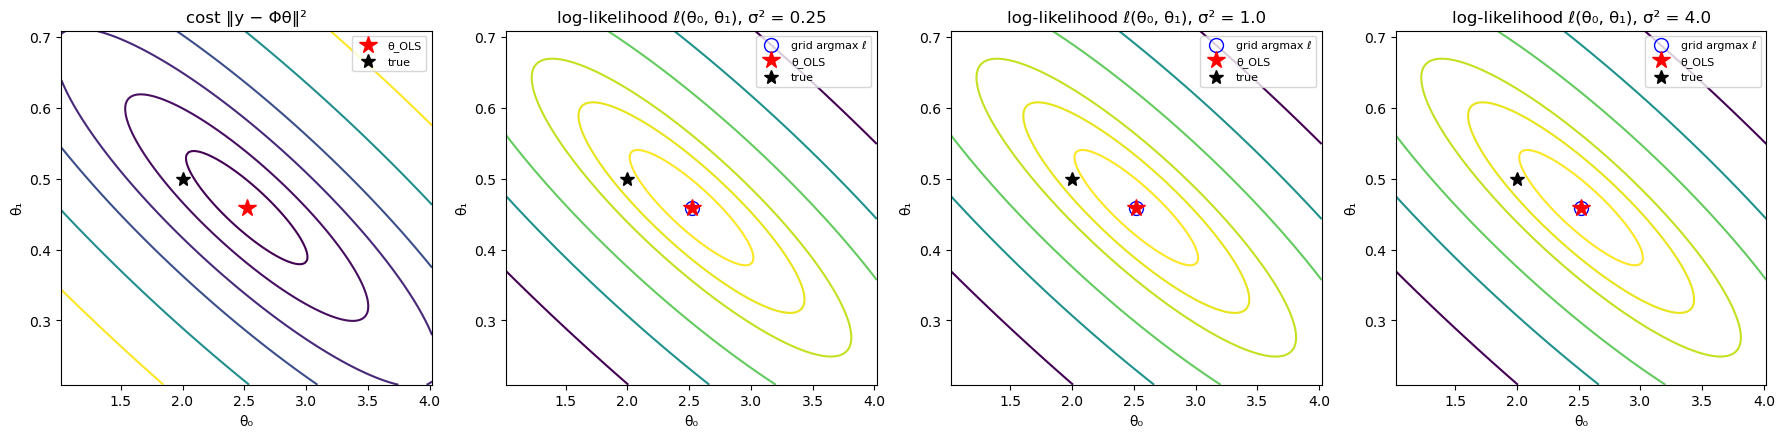

In [14]:
rng = np.random.default_rng(0)
m_r, sigma = 40, 1.0
x = np.sort(rng.uniform(0, 10, m_r))
y_r = 2 + 0.5 * x + rng.normal(0, sigma, m_r)
Phi = np.column_stack([np.ones(m_r), x])

theta_ols = np.linalg.solve(Phi.T @ Phi, Phi.T @ y_r)

def cost(t0, t1):
    R = y_r[:, None, None] - (t0 + t1 * x[:, None, None])
    return np.sum(R**2, axis=0)

def loglik_reg(t0, t1, s2):
    return -m_r / 2 * np.log(2 * np.pi * s2) - cost(t0, t1) / (2 * s2)

T0, T1 = np.meshgrid(np.linspace(theta_ols[0] - 1.5, theta_ols[0] + 1.5, 161), np.linspace(theta_ols[1] - 0.25, theta_ols[1] + 0.25, 161))
fig, axes = plt.subplots(1, 4, figsize=(22, 4.6))
C = cost(T0, T1)
axes[0].contour(T0, T1, C, levels=C.min() * np.array([1.05, 1.2, 1.5, 2, 3, 5]), cmap="viridis")
axes[0].set_title("cost ‖y − Φθ‖²")
for ax, s2 in zip(axes[1:], [0.25, 1.0, 4.0]):
    Lr = loglik_reg(T0, T1, s2)
    th_ml = np.array([T0.flat[Lr.argmax()], T1.flat[Lr.argmax()]])
    ax.contour(T0, T1, Lr, levels=Lr.max() - np.array([20, 10, 5, 2, 1, 0.3]) * 4 / s2, cmap="viridis")
    ax.plot(*th_ml, "bo", ms=10, mfc="none", label="grid argmax ℓ")
    ax.set_title(f"log-likelihood ℓ(θ₀, θ₁), σ² = {s2}")
for ax in axes:
    ax.plot(*theta_ols, "r*", ms=13, label="θ_OLS"); ax.plot(2, 0.5, "k*", ms=10, label="true")
    ax.set_xlabel("θ₀"); ax.set_ylabel("θ₁"); ax.legend(fontsize=8)
plt.show()

### Verify numerically, and the noise-variance estimators

In [15]:
nll = lambda th, s2: -(-m_r / 2 * np.log(2 * np.pi * s2) - np.sum((y_r - Phi @ th) ** 2) / (2 * s2))
for s2 in [0.25, 1.0, 4.0]:
    th_ml = minimize(lambda th: nll(th, s2), x0=[0.0, 0.0]).x
    check(f"σ² = {s2}: θ_ML (numerical) = θ_OLS", np.allclose(th_ml, theta_ols, atol=1e-4))
res = y_r - Phi @ theta_ols
p = Phi.shape[1]
s2_ml, s2_unb = res @ res / m_r, res @ res / (m_r - p)
joint = minimize(lambda v: nll(v[:2], np.exp(v[2])), x0=[0, 0, 0]).x
print(f"σ²_ML = RSS/m = {s2_ml:.4f}    unbiased RSS/(m − p) = {s2_unb:.4f}    (true σ² = {sigma**2})")
check("joint ML over (θ, σ²) gives σ² = RSS/m", np.isclose(np.exp(joint[2]), s2_ml, rtol=1e-3))
check("Φᵀ(y − Φθ̂) = 0 (normal equations)", np.allclose(Phi.T @ res, 0, atol=1e-9))

✓  σ² = 0.25: θ_ML (numerical) = θ_OLS
✓  σ² = 1.0: θ_ML (numerical) = θ_OLS
✓  σ² = 4.0: θ_ML (numerical) = θ_OLS
σ²_ML = RSS/m = 1.1572    unbiased RSS/(m − p) = 1.2181    (true σ² = 1.0)
✓  joint ML over (θ, σ²) gives σ² = RSS/m
✓  Φᵀ(y − Φθ̂) = 0 (normal equations)


### What if the noise is Laplacian?

With $\epsilon_i \sim \mathrm{Laplace}(0, b)$, $f(\epsilon) = \frac{1}{2b}e^{-|\epsilon|/b}$:
$$\ell(\theta, b) = -m\log(2b) - \frac1b\sum_i|y_i - \theta^\top\phi(x_i)|,$$
so ML minimises the sum of **absolute** residuals (least absolute deviations), and $\hat b_{ML} = \frac1m\sum|r_i|$. Below: the same data plus three outliers, fitted both ways.

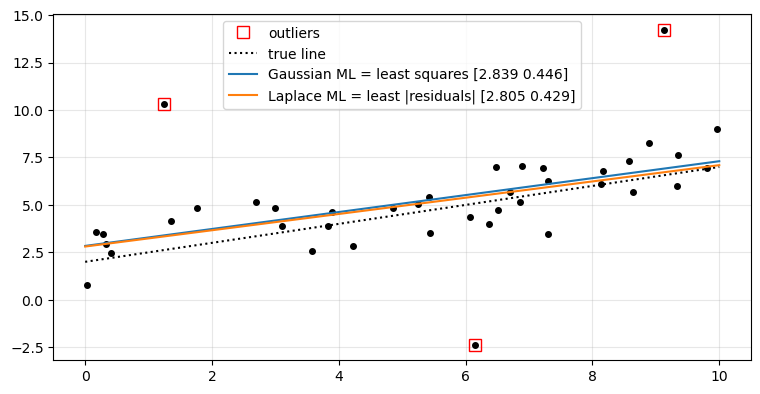

In [16]:
y_out = y_r.copy(); y_out[[5, 20, 35]] += np.array([8, -7, 9])
th_ls = np.linalg.lstsq(Phi, y_out, rcond=None)[0]
th_lad = minimize(lambda th: np.sum(np.abs(y_out - Phi @ th)), x0=th_ls, method="Nelder-Mead",
                  options=dict(xatol=1e-8, fatol=1e-8)).x
xx = np.linspace(0, 10, 2)
plt.figure(figsize=(9, 4.5))
plt.plot(x, y_out, "ko", ms=4); plt.plot(x[[5, 20, 35]], y_out[[5, 20, 35]], "rs", ms=8, mfc="none", label="outliers")
plt.plot(xx, 2 + 0.5 * xx, "k:", label="true line")
plt.plot(xx, th_ls[0] + th_ls[1] * xx, label=f"Gaussian ML = least squares {th_ls.round(3)}")
plt.plot(xx, th_lad[0] + th_lad[1] * xx, label=f"Laplace ML = least |residuals| {th_lad.round(3)}")
plt.legend(); plt.grid(alpha=0.3); plt.show()

---
### Explain

**1. Why do both plots have the same maximiser/minimiser for any value of $\sigma^2$ [MLE 1.6.2]?**

$\ell(\theta,\sigma^2) = -\frac m2\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\|y-\Phi\theta\|^2$. For fixed $\sigma^2$ the first term does not depend on $\theta$ and the second is the cost multiplied by the negative constant $-1/(2\sigma^2)$. Multiplying by a negative constant turns minimisation into maximisation and adding a constant changes nothing, so $\arg\max_\theta\ell = \arg\min_\theta\|y - \Phi\theta\|^2 = \hat\theta_{OLS}$ for every $\sigma^2 > 0$ (checked for $\sigma^2 = 0.25, 1, 4$). $\sigma^2$ only rescales the contour *values*: the plots show the same ellipses with different spacing.

**2. Compute $\hat\sigma^2_{ML}$ and the unbiased version.**

Setting $\partial\ell/\partial\sigma^2 = 0$ at $\hat\theta$ gives $\hat\sigma^2_{ML} = \frac{1}{m}\|y - \Phi\hat\theta\|^2 = \mathrm{RSS}/m$ (the joint numerical maximisation agrees). The unbiased version is $\mathrm{RSS}/(m-p)$, where $p$ is the number of columns of $\Phi$ ($p = 2$ here: intercept and slope), because the residual vector lives in the $(m-p)$-dimensional left null space of $\Phi$, so $E(\mathrm{RSS}) = (m-p)\sigma^2$. (The notes write $m-p-1$, which corresponds to counting $p$ as the number of regressors *excluding* the intercept.) With $m = 40$ the two differ by 5%; the printed values are both close to the true $\sigma^2 = 1$.

**3. What changes if the noise is Laplacian instead of Gaussian (write the new log-likelihood)?**

$\ell(\theta, b) = -m\log(2b) - \frac1b\sum_i|y_i - \theta^\top\phi(x_i)|$. The ML estimate of $\theta$ now minimises $\|y - \Phi\theta\|_1$ (least absolute deviations) for any $b$, and $\hat b = \frac1m\|y-\Phi\hat\theta\|_1$. Differences from least squares: (i) there is no closed form; it is a convex but non-differentiable problem, solvable as an LP (minimise $\sum t_i$ with $-t_i \le y_i - \phi_i^\top\theta \le t_i$); (ii) it is **robust to outliers**: each residual contributes linearly instead of quadratically, so a few large errors cannot drag the fit (in the plot the LS line is pulled towards the outliers, the Laplace line stays near the truth); (iii) it corresponds to a heavier-tailed noise model, which is exactly why large residuals are "expected" and not penalised much. The fitted line is like a median, where least squares is like a mean.